# 09 — Global finalists and benchmark freeze

Notebook 08 tested robustness dimensions separately. This notebook combines the best choices and freezes the global benchmark that future interaction and separate-model experiments must beat.

Selection discipline:

- 2022–2024 are development evaluation years.
- 2025 is reported separately as a confirmation year. It is not perfectly pristine because earlier notebooks already inspected 2025, so results remain research evidence rather than a claim of untouched production validation.
- Every finalist tunes its ridge penalty using the immediately preceding historical year only.
- A model within 0.002 mean development log RMSE of the best is considered practically tied; among tied models, fewer source features are preferred.
- Raw WAPE, bias, tail behavior, and stability are reported alongside the primary log-RMSE criterion.

In [1]:
from pathlib import Path
import sys
import warnings

import duckdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 160)
pd.set_option("display.max_rows", 160)
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (12, 7), "figure.dpi": 120})

cwd = Path.cwd().resolve()
PROJECT_ROOT = next((p for p in [cwd, *cwd.parents] if (p / "blackrock_data").exists()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Could not locate blackrock_data.")
sys.path.insert(0, str(PROJECT_ROOT))

from notebooks.modeling_utils import (
    fit_preprocessor, apply_preprocessor, fit_ridge, predict_ridge, forecast_metrics
)

PANEL = PROJECT_ROOT / "outputs" / "eda" / "05_feature_engineering" / "enriched_daily_panel.parquet"
CATALOG = PROJECT_ROOT / "outputs" / "eda" / "05_feature_engineering" / "approved_enriched_daily_features.csv"
OUT = PROJECT_ROOT / "outputs" / "eda" / "09_global_finalists"
PREDICTIONS = OUT / "predictions"
OUT.mkdir(parents=True, exist_ok=True)
PREDICTIONS.mkdir(parents=True, exist_ok=True)

con = duckdb.connect()
con.execute("PRAGMA threads=4")

def sql(query, params=None):
    return con.execute(query, params or []).df()

catalog = pd.read_csv(CATALOG)
FEATURES = catalog["variable"].tolist()
FEATURE_GROUPS = catalog.groupby("group")["variable"].apply(list).to_dict()

## Predeclared finalists

In [2]:
BOOLEAN_FEATURES = [
    "auction_spike_lag1", "is_monday", "is_friday",
    "is_first_trading_day_month", "is_last_trading_day_month",
    "is_last_3_trading_days_month", "is_last_5_trading_days_month",
    "is_last_trading_day_quarter", "is_last_3_trading_days_quarter",
    "is_last_5_trading_days_quarter", "is_last_trading_day_year",
    "monthly_options_expiry", "quarterly_options_expiry",
    "after_long_market_gap", "before_long_market_gap", "is_early_close",
    "early_close_month_end_window", "expiry_month_end_window",
    "lag1_dividend_flag", "lag1_distribution_flag", "lag1_price_adjustment_flag",
]
CATEGORICAL_FEATURES = ["month", "day_of_week", "ff12_code", "size_decile", "liquidity_decile"]
CONTINUOUS_FEATURES = [f for f in FEATURES if f not in BOOLEAN_FEATURES and f not in CATEGORICAL_FEATURES]

AUCTION_CALENDAR = list(dict.fromkeys(
    FEATURE_GROUPS["Auction history"] + FEATURE_GROUPS["Calendar"]
))
AUCTION_CALENDAR_LIQUIDITY = list(dict.fromkeys(
    AUCTION_CALENDAR + FEATURE_GROUPS["Liquidity"]
))

FINALISTS = {
    "expanding_log_full": {
        "window": "expanding", "target": "log_level", "weight": "uniform", "features": FEATURES,
    },
    "rolling5_log_full": {
        "window": "rolling5", "target": "log_level", "weight": "uniform", "features": FEATURES,
    },
    "rolling5_residual_full": {
        "window": "rolling5", "target": "median20_residual", "weight": "uniform", "features": FEATURES,
    },
    "rolling3_residual_full": {
        "window": "rolling3", "target": "median20_residual", "weight": "uniform", "features": FEATURES,
    },
    "rolling5_residual_recent_full": {
        "window": "rolling5", "target": "median20_residual", "weight": "recent", "features": FEATURES,
    },
    "rolling5_residual_auction_calendar": {
        "window": "rolling5", "target": "median20_residual", "weight": "uniform",
        "features": AUCTION_CALENDAR,
    },
    "rolling5_residual_auction_calendar_liquidity": {
        "window": "rolling5", "target": "median20_residual", "weight": "uniform",
        "features": AUCTION_CALENDAR_LIQUIDITY,
    },
}

finalist_table = pd.DataFrame([
    {"candidate": name, "window": spec["window"], "target": spec["target"],
     "weight": spec["weight"], "source_feature_count": len(spec["features"])}
    for name, spec in FINALISTS.items()
])
display(finalist_table)
finalist_table.to_csv(OUT / "finalist_specifications.csv", index=False)

,candidate,window,target,weight,source_feature_count
0,expanding_log_full,expanding,log_level,uniform,99
1,rolling5_log_full,rolling5,log_level,uniform,99
2,rolling5_residual_full,rolling5,median20_residual,uniform,99
3,rolling3_residual_full,rolling3,median20_residual,uniform,99
4,rolling5_residual_recent_full,rolling5,median20_residual,recent,99
5,rolling5_residual_auction_calendar,rolling5,median20_residual,uniform,42
6,rolling5_residual_auction_calendar_liquidity,rolling5,median20_residual,uniform,58


## Shared query and estimation helpers

In [3]:
TEST_YEARS = [2022, 2023, 2024, 2025]
DEVELOPMENT_YEARS = [2022, 2023, 2024]
CONFIRMATION_YEAR = 2025
LAMBDA_GRID = [1e-7, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]
TUNE_ROWS = 250_000
VALIDATION_ROWS = 120_000
REFIT_ROWS = 350_000
SEED = 20261012

CONTEXT = [
    "date", "permno", "auction_volume", "log1p_auction_volume",
    "median20_auction_volume", "avg20_daily_volume",
    "size_percentile", "liquidity_percentile", "auction_intensity_percentile",
    "prior_auction_observations", "quarterly_options_expiry", "monthly_options_expiry",
    "is_last_trading_day_month", "is_early_close",
]
QUERY_COLUMNS = list(dict.fromkeys(CONTEXT + FEATURES))
QUOTED_COLUMNS = ", ".join(f'"{c}"' for c in QUERY_COLUMNS)

def load_period(start_date, end_date, sample_rows=None, seed=SEED):
    sample_clause = f"USING SAMPLE {sample_rows} ROWS (reservoir, {seed})" if sample_rows else ""
    return sql(f"""
        SELECT * FROM (
            SELECT {QUOTED_COLUMNS}
            FROM read_parquet('{PANEL}')
            WHERE eligible_target
              AND date >= DATE '{start_date}' AND date < DATE '{end_date}'
        ) {sample_clause}
    """)

def window_start(end_year, window):
    if window == "expanding":
        return "2015-01-01"
    years = int(window.replace("rolling", ""))
    return f"{end_year - years}-01-01"

def feature_mask(prep, source_features):
    allowed = set(source_features)
    return np.array([source in allowed for source in prep["output_sources"]])

def training_weights(frame, specification, prediction_year):
    if specification["weight"] == "uniform":
        return None
    age_years = (
        pd.Timestamp(f"{prediction_year}-01-01") - pd.to_datetime(frame["date"])
    ).dt.days.to_numpy() / 365.25
    return np.power(0.5, age_years / 2.0)

def model_target_and_base(train, score, specification):
    y_train_log = train["log1p_auction_volume"].to_numpy(dtype=float)
    if specification["target"] == "log_level":
        return y_train_log, np.zeros(len(score)), np.median(train["auction_volume"])
    fallback = float(np.median(train["auction_volume"]))
    train_base = train["median20_auction_volume"].fillna(fallback).to_numpy(dtype=float)
    score_base = score["median20_auction_volume"].fillna(fallback).to_numpy(dtype=float)
    return y_train_log - np.log1p(train_base), np.log1p(score_base), fallback

def fit_score_candidate(train, score, x_train, x_score, mask, specification, strength, prediction_year):
    target, score_base_log, fallback = model_target_and_base(train, score, specification)
    weights = training_weights(train, specification, prediction_year)
    coef = fit_ridge(x_train[:, mask], target, strength, weights)
    component = predict_ridge(x_score[:, mask], coef)
    final_log = component + score_base_log
    y_train_log = train["log1p_auction_volume"].to_numpy(dtype=float)
    lo, hi = np.quantile(y_train_log, [0.001, 0.999])
    return np.clip(final_log, lo, hi), coef, fallback

## Nested tuning and out-of-time finalist forecasts

Matrices are shared among finalists with the same history window, while each candidate receives its own feature mask, target, weights, and selected penalty.

In [4]:
metric_rows = []
lambda_rows = []
coefficient_rows = []

for test_year in TEST_YEARS:
    print(f"Running finalists for {test_year}...")
    test = load_period(f"{test_year}-01-01", f"{test_year + 1}-01-01")
    output = test[CONTEXT].copy()
    y_test_raw = test["auction_volume"].to_numpy(dtype=float)

    for window in sorted({spec["window"] for spec in FINALISTS.values()}):
        candidates = {name: spec for name, spec in FINALISTS.items() if spec["window"] == window}
        validation_year = test_year - 1
        tune_train = load_period(
            window_start(validation_year, window), f"{validation_year}-01-01",
            TUNE_ROWS, SEED + test_year + len(window),
        )
        validation = load_period(
            f"{validation_year}-01-01", f"{test_year}-01-01",
            VALIDATION_ROWS, SEED + 100 + test_year + len(window),
        )
        x_tune, prep_tune = fit_preprocessor(
            tune_train, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
        )
        x_validation = apply_preprocessor(
            validation, prep_tune, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
        )

        selected = {}
        for name, spec in candidates.items():
            mask = feature_mask(prep_tune, spec["features"])
            best_strength, best_rmse = None, np.inf
            for strength in LAMBDA_GRID:
                pred_log, _, _ = fit_score_candidate(
                    tune_train, validation, x_tune, x_validation, mask,
                    spec, strength, validation_year,
                )
                rmse = np.sqrt(np.mean(
                    (validation["log1p_auction_volume"].to_numpy(dtype=float) - pred_log) ** 2
                ))
                lambda_rows.append({
                    "test_year": test_year, "candidate": name,
                    "validation_year": validation_year, "ridge_strength": strength,
                    "validation_rmse_log": rmse,
                })
                if rmse < best_rmse:
                    best_strength, best_rmse = strength, rmse
            selected[name] = (best_strength, best_rmse)

        refit = load_period(
            window_start(test_year, window), f"{test_year}-01-01",
            REFIT_ROWS, SEED + 200 + test_year + len(window),
        )
        x_refit, prep = fit_preprocessor(
            refit, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
        )
        x_test = apply_preprocessor(
            test, prep, CONTINUOUS_FEATURES, BOOLEAN_FEATURES, CATEGORICAL_FEATURES
        )

        for name, spec in candidates.items():
            strength, validation_rmse = selected[name]
            mask = feature_mask(prep, spec["features"])
            pred_log, coef, fallback = fit_score_candidate(
                refit, test, x_refit, x_test, mask, spec, strength, test_year,
            )
            pred_raw = np.expm1(pred_log)
            output[name] = pred_raw
            metric_rows.append({
                "test_year": test_year, "candidate": name,
                "selected_lambda": strength, "validation_rmse_log": validation_rmse,
                **forecast_metrics(y_test_raw, pred_raw),
            })
            selected_names = np.asarray(prep["output_names"])[mask]
            selected_sources = np.asarray(prep["output_sources"])[mask]
            coefficient_rows.extend([
                {"test_year": test_year, "candidate": name, "output_feature": "INTERCEPT",
                 "source_feature": "INTERCEPT", "coefficient": coef[0]},
                *[
                    {"test_year": test_year, "candidate": name, "output_feature": out_name,
                     "source_feature": source, "coefficient": value}
                    for out_name, source, value in zip(selected_names, selected_sources, coef[1:])
                ],
            ])
        del tune_train, validation, refit, x_tune, x_validation, x_refit, x_test

    prediction_path = PREDICTIONS / f"global_finalist_predictions_{test_year}.parquet"
    con.register("global_finalist_output", output)
    con.execute(f"COPY global_finalist_output TO '{prediction_path}' (FORMAT PARQUET, COMPRESSION ZSTD)")
    con.unregister("global_finalist_output")
    print(f"  wrote {len(output):,} predictions")

metrics = pd.DataFrame(metric_rows)
lambda_results = pd.DataFrame(lambda_rows)
coefficients = pd.DataFrame(coefficient_rows)
metrics.to_csv(OUT / "global_finalist_metrics.csv", index=False)
lambda_results.to_csv(OUT / "global_finalist_lambda_validation.csv", index=False)
coefficients.to_csv(OUT / "global_finalist_coefficients.csv", index=False)
display(metrics.sort_values(["test_year", "rmse_log"]))

Running finalists for 2022...


  wrote 328,634 predictions
Running finalists for 2023...


  wrote 318,679 predictions
Running finalists for 2024...


  wrote 316,212 predictions
Running finalists for 2025...


  wrote 307,853 predictions


,test_year,candidate,selected_lambda,validation_rmse_log,observations,mae_raw,wape,mae_log,rmse_log,spearman,aggregate_bias
4,2022,rolling5_residual_recent_full,0.0001,0.5989,328634,"74,027.5318",0.3804,0.3646,0.5332,0.9489,-0.1466
1,2022,rolling3_residual_full,0.0001,0.5980,328634,"73,661.3296",0.3785,0.3651,0.5333,0.9489,-0.1511
6,2022,rolling5_residual_auction_calendar_liquidity,0.0001,0.5995,328634,"74,158.2867",0.3811,0.3638,0.5335,0.9490,-0.1444
3,2022,rolling5_residual_full,0.0001,0.5997,328634,"74,166.3326",0.3811,0.3650,0.5341,0.9488,-0.1437
5,2022,rolling5_residual_auction_calendar,0.0001,0.6040,328634,"74,394.3641",0.3823,0.3660,0.5365,0.9484,-0.1417
2,2022,rolling5_log_full,0.0001,0.6079,328634,"75,196.8510",0.3864,0.3691,0.5432,0.9485,-0.1466
0,2022,expanding_log_full,0.0000,0.6118,328634,"75,990.8882",0.3905,0.3709,0.5467,0.9483,-0.1487
11,2023,rolling5_residual_recent_full,0.0000,0.5341,318679,"81,101.8801",0.3681,0.3339,0.4819,0.9565,-0.1416
10,2023,rolling5_residual_full,0.0001,0.5350,318679,"81,052.6399",0.3679,0.3342,0.4823,0.9565,-0.1428
13,2023,rolling5_residual_auction_calendar_liquidity,0.0001,0.5345,318679,"81,455.0318",0.3697,0.3348,0.4837,0.9562,-0.1416


## Development selection and 2025 confirmation

The primary development metric is mean annual log RMSE over 2022–2024. Candidates no more than 0.002 above the best are considered practically tied; the candidate with the fewest source features is selected from that set, with RMSE breaking any remaining tie.

In [5]:
dev = metrics[metrics["test_year"].isin(DEVELOPMENT_YEARS)].groupby("candidate").agg(
    development_rmse_log=("rmse_log", "mean"),
    development_wape=("wape", "mean"),
    development_spearman=("spearman", "mean"),
    development_bias=("aggregate_bias", "mean"),
    worst_development_rmse=("rmse_log", "max"),
).reset_index().merge(finalist_table[["candidate", "source_feature_count"]], on="candidate")

best_rmse = dev["development_rmse_log"].min()
dev["within_practical_tolerance"] = dev["development_rmse_log"] <= best_rmse + 0.002
eligible = dev[dev["within_practical_tolerance"]].sort_values(
    ["source_feature_count", "development_rmse_log"]
)
CHAMPION = eligible.iloc[0]["candidate"]

confirmation = metrics[metrics["test_year"] == CONFIRMATION_YEAR].merge(
    finalist_table[["candidate", "source_feature_count"]], on="candidate"
).sort_values("rmse_log")
selection_table = dev.merge(
    confirmation[["candidate", "rmse_log", "wape", "spearman", "aggregate_bias"]].rename(columns={
        "rmse_log": "confirmation_rmse_log", "wape": "confirmation_wape",
        "spearman": "confirmation_spearman", "aggregate_bias": "confirmation_bias",
    }), on="candidate"
).sort_values("development_rmse_log")
selection_table["selected_global_champion"] = selection_table["candidate"] == CHAMPION
selection_table.to_csv(OUT / "global_finalist_selection.csv", index=False)

print(f"Selected global champion: {CHAMPION}")
display(selection_table)

Selected global champion: rolling5_residual_auction_calendar_liquidity


,candidate,development_rmse_log,development_wape,development_spearman,development_bias,worst_development_rmse,source_feature_count,within_practical_tolerance,confirmation_rmse_log,confirmation_wape,confirmation_spearman,confirmation_bias,selected_global_champion
6,rolling5_residual_recent_full,0.4868,0.3673,0.9549,-0.1398,0.5332,99,True,0.4461,0.3414,0.9593,-0.1261,False
5,rolling5_residual_full,0.4871,0.3669,0.9549,-0.1438,0.5341,99,True,0.4501,0.3413,0.9589,-0.1415,False
4,rolling5_residual_auction_calendar_liquidity,0.4876,0.3680,0.9549,-0.1438,0.5335,58,True,0.4451,0.3456,0.9588,-0.0962,True
3,rolling5_residual_auction_calendar,0.4906,0.3690,0.9544,-0.1398,0.5365,42,False,0.4479,0.3473,0.9584,-0.0915,False
1,rolling3_residual_full,0.4922,0.3674,0.9545,-0.1402,0.5333,99,False,0.4489,0.3413,0.9594,-0.1352,False
2,rolling5_log_full,0.4961,0.3717,0.9547,-0.1437,0.5432,99,False,0.4532,0.3463,0.9585,-0.1523,False
0,expanding_log_full,0.4990,0.3767,0.9544,-0.1368,0.5467,99,False,0.4512,0.3533,0.9584,-0.1105,False


## Paired date-block uncertainty

Every finalist is compared with the original expanding/full/log candidate on identical dates and stock-days. The champion is also compared with the best non-champion development candidate. Intervals are reported separately for development dates and the 2025 confirmation dates.

In [6]:
REFERENCE = "expanding_log_full"
runner_up = selection_table[selection_table["candidate"] != CHAMPION].iloc[0]["candidate"]
PREDICTION_GLOB = str(PREDICTIONS / "global_finalist_predictions_*.parquet")

comparisons = [(candidate, REFERENCE) for candidate in FINALISTS if candidate != REFERENCE]
if (CHAMPION, runner_up) not in comparisons:
    comparisons.append((CHAMPION, runner_up))

rng = np.random.default_rng(SEED)
bootstrap_rows = []
for candidate, reference in comparisons:
    daily = sql(f"""
        SELECT date, year(date) AS test_year,
               avg(abs(ln(1 + \"{candidate}\") - log1p_auction_volume)
                   - abs(ln(1 + \"{reference}\") - log1p_auction_volume)) AS log_mae_difference,
               sum(abs(\"{candidate}\" - auction_volume)) / sum(auction_volume)
                   - sum(abs(\"{reference}\" - auction_volume)) / sum(auction_volume)
                   AS daily_wape_difference
        FROM read_parquet('{PREDICTION_GLOB}') GROUP BY date
    """)
    for period, subset in {
        "development_2022_2024": daily[daily["test_year"].isin(DEVELOPMENT_YEARS)],
        "confirmation_2025": daily[daily["test_year"] == CONFIRMATION_YEAR],
    }.items():
        for metric in ["log_mae_difference", "daily_wape_difference"]:
            values = subset[metric].dropna().to_numpy()
            draws = np.empty(3000)
            for i in range(len(draws)):
                draws[i] = rng.choice(values, size=len(values), replace=True).mean()
            bootstrap_rows.append({
                "candidate": candidate, "reference": reference, "period": period,
                "metric": metric, "mean_difference": values.mean(),
                "ci_2_5": np.quantile(draws, 0.025), "ci_97_5": np.quantile(draws, 0.975),
                "dates": len(values),
            })

bootstrap = pd.DataFrame(bootstrap_rows)
bootstrap.to_csv(OUT / "global_finalist_date_block_bootstrap.csv", index=False)
display(bootstrap[(bootstrap["candidate"] == CHAMPION) | (bootstrap["reference"] == CHAMPION)])

,candidate,reference,period,metric,mean_difference,ci_2_5,ci_97_5,dates
20,rolling5_residual_auction_calendar_liquidity,expanding_log_full,development_2022_2024,log_mae_difference,-0.0069,-0.0080,-0.0057,753
21,rolling5_residual_auction_calendar_liquidity,expanding_log_full,development_2022_2024,daily_wape_difference,-0.0092,-0.0106,-0.0078,753
22,rolling5_residual_auction_calendar_liquidity,expanding_log_full,confirmation_2025,log_mae_difference,-0.0051,-0.0072,-0.0029,250
23,rolling5_residual_auction_calendar_liquidity,expanding_log_full,confirmation_2025,daily_wape_difference,-0.0079,-0.0105,-0.0054,250
24,rolling5_residual_auction_calendar_liquidity,rolling5_residual_recent_full,development_2022_2024,log_mae_difference,-0.0000,-0.0008,0.0007,753
25,rolling5_residual_auction_calendar_liquidity,rolling5_residual_recent_full,development_2022_2024,daily_wape_difference,0.0010,0.0002,0.0018,753
26,rolling5_residual_auction_calendar_liquidity,rolling5_residual_recent_full,confirmation_2025,log_mae_difference,0.0025,0.0005,0.0045,250
27,rolling5_residual_auction_calendar_liquidity,rolling5_residual_recent_full,confirmation_2025,daily_wape_difference,0.0052,0.0034,0.0073,250


## Champion tail, segment, and sign diagnostics

Freezing the benchmark does not mean its errors are homogeneous. The final diagnostics identify where future interaction or specialist models must improve.

In [7]:
segment_diagnostics = sql(f"""
WITH base AS (
    SELECT *,
           CASE WHEN size_percentile < 1.0/3 THEN 'small'
                WHEN size_percentile < 2.0/3 THEN 'mid' ELSE 'large' END AS size_segment,
           CASE WHEN liquidity_percentile < 1.0/3 THEN 'low'
                WHEN liquidity_percentile < 2.0/3 THEN 'mid' ELSE 'high' END AS liquidity_segment,
           CASE WHEN auction_intensity_percentile < 1.0/3 THEN 'low'
                WHEN auction_intensity_percentile < 2.0/3 THEN 'mid' ELSE 'high' END AS intensity_segment,
           CASE WHEN prior_auction_observations < 5 THEN 'cold_0_4'
                WHEN prior_auction_observations < 20 THEN 'developing_5_19'
                ELSE 'seasoned_20_plus' END AS history_segment,
           CASE WHEN quarterly_options_expiry THEN 'quarterly_expiry'
                WHEN monthly_options_expiry THEN 'monthly_expiry'
                WHEN is_last_trading_day_month THEN 'month_end'
                WHEN is_early_close THEN 'early_close' ELSE 'regular' END AS event_segment,
           percent_rank() OVER (PARTITION BY year(date) ORDER BY auction_volume) AS actual_percentile
    FROM read_parquet('{PREDICTION_GLOB}')
), long_segments AS (
    SELECT date, auction_volume, log1p_auction_volume, "{CHAMPION}" AS prediction,
           'size' AS dimension, size_segment AS segment FROM base
    UNION ALL SELECT date, auction_volume, log1p_auction_volume, "{CHAMPION}",
           'liquidity', liquidity_segment FROM base
    UNION ALL SELECT date, auction_volume, log1p_auction_volume, "{CHAMPION}",
           'auction_intensity', intensity_segment FROM base
    UNION ALL SELECT date, auction_volume, log1p_auction_volume, "{CHAMPION}",
           'history', history_segment FROM base
    UNION ALL SELECT date, auction_volume, log1p_auction_volume, "{CHAMPION}",
           'event', event_segment FROM base
    UNION ALL SELECT date, auction_volume, log1p_auction_volume, "{CHAMPION}",
           'actual_tail', CASE WHEN actual_percentile >= 0.99 THEN 'top_1pct' ELSE 'lower_99pct' END FROM base
)
SELECT dimension, segment, count(*) AS observations,
       sqrt(avg(pow(ln(1 + prediction) - log1p_auction_volume, 2))) AS rmse_log,
       sum(abs(prediction - auction_volume)) / sum(auction_volume) AS wape,
       sum(prediction) / sum(auction_volume) - 1 AS aggregate_bias
FROM long_segments GROUP BY dimension, segment ORDER BY dimension, segment
""")
segment_diagnostics.to_csv(OUT / "champion_segment_and_tail_diagnostics.csv", index=False)
display(segment_diagnostics)

champion_coef = coefficients[
    (coefficients["candidate"] == CHAMPION)
    & (coefficients["output_feature"] == coefficients["source_feature"])
    & (coefficients["source_feature"] != "INTERCEPT")
]
champion_signs = champion_coef.groupby("source_feature").agg(
    estimates=("coefficient", "size"),
    mean_coefficient=("coefficient", "mean"),
    sign_consistency=("coefficient", lambda s: max((s > 0).mean(), (s < 0).mean())),
    minimum=("coefficient", "min"), maximum=("coefficient", "max"),
).reset_index()
champion_signs.to_csv(OUT / "champion_coefficient_stability.csv", index=False)
display(champion_signs.sort_values("sign_consistency").head(20))

,dimension,segment,observations,rmse_log,wape,aggregate_bias
0,actual_tail,lower_99pct,1258662,0.4643,0.3139,-0.0573
1,actual_tail,top_1pct,12716,1.2714,0.5424,-0.4109
2,auction_intensity,high,399393,0.4536,0.3523,-0.1353
3,auction_intensity,low,433246,0.5582,0.3927,-0.1474
4,auction_intensity,mid,438739,0.4128,0.3380,-0.1070
5,event,early_close,8742,0.4362,0.2990,-0.0747
6,event,month_end,61010,0.6593,0.4912,-0.1968
7,event,monthly_expiry,40566,0.5331,0.3694,-0.1119
8,event,quarterly_expiry,20378,0.7885,0.5523,-0.2280
9,event,regular,1140682,0.4582,0.3201,-0.1093


,source_feature,estimates,mean_coefficient,sign_consistency,minimum,maximum
18,expiry_month_end_window,4,0.0000,0.0000,0.0000,0.0000
27,is_last_trading_day_quarter,4,0.0244,0.5000,-0.0378,0.0804
53,trading_days_to_quarter_end,4,0.0580,0.5000,-0.0765,0.2918
54,trading_days_to_year_end,4,-0.2072,0.5000,-0.8124,0.0181
13,avg60_auction_volume,4,-0.0145,0.5000,-0.0390,0.0076
24,is_last_5_trading_days_month,4,-0.0010,0.7500,-0.0085,0.0131
20,is_first_trading_day_month,4,0.0000,0.7500,-0.0068,0.0172
44,prior_auction_observations,4,-0.0046,0.7500,-0.0084,0.0004
30,lag1_amihud,4,-0.0013,0.7500,-0.0037,0.0008
52,trading_days_to_month_end,4,-0.0472,0.7500,-0.0934,0.0084


## Final comparison visualization

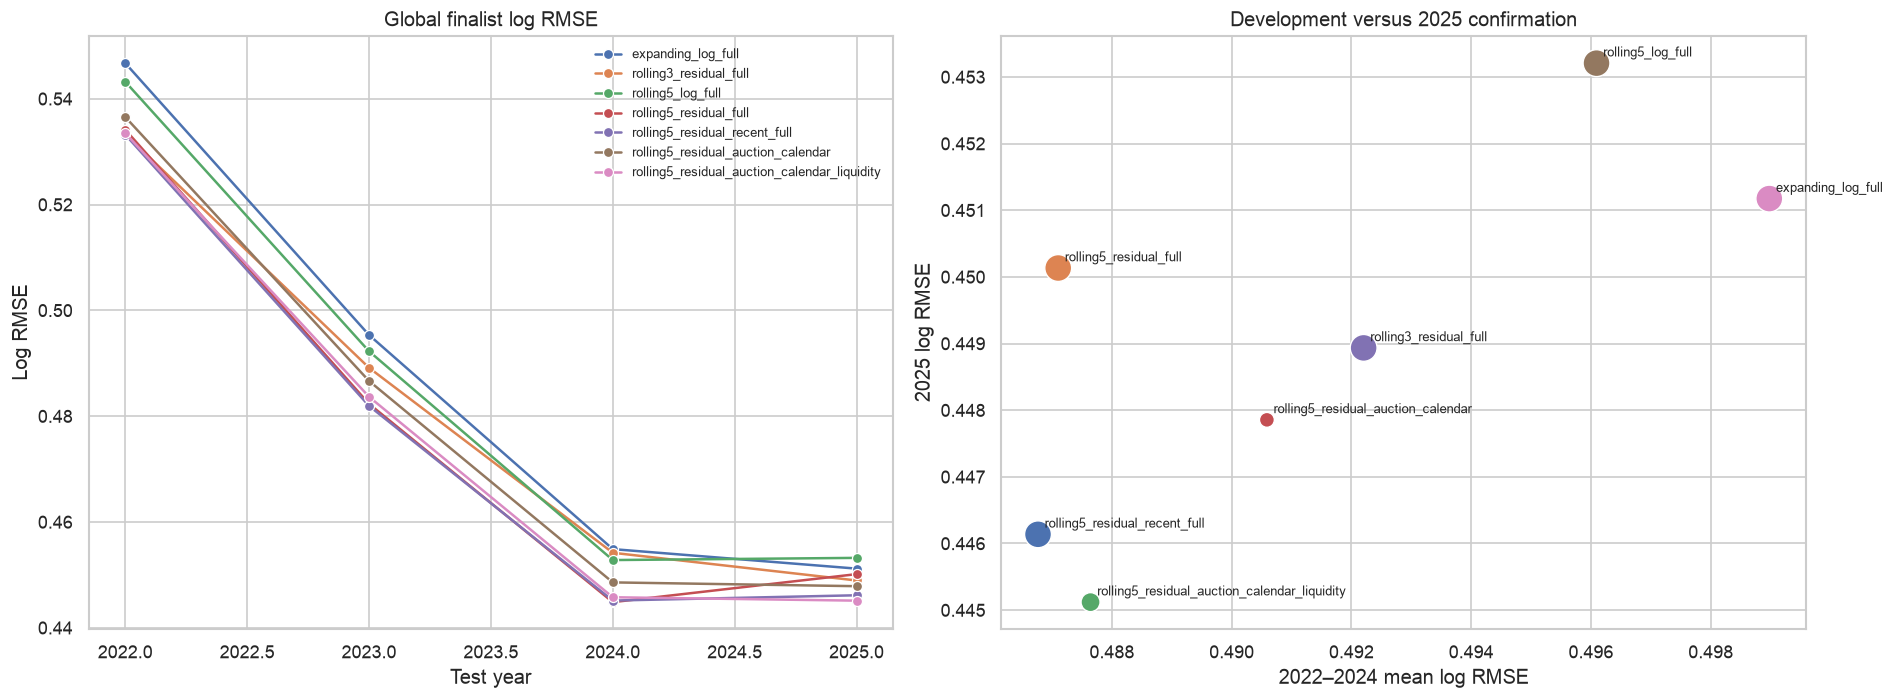

In [8]:
plot_metrics = metrics.merge(finalist_table[["candidate", "source_feature_count"]], on="candidate")
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.lineplot(data=plot_metrics, x="test_year", y="rmse_log", hue="candidate", marker="o", ax=axes[0])
axes[0].set(title="Global finalist log RMSE", xlabel="Test year", ylabel="Log RMSE")
axes[0].legend(fontsize=8, frameon=False)
selection_plot = selection_table.sort_values("development_rmse_log")
sns.scatterplot(
    data=selection_plot, x="development_rmse_log", y="confirmation_rmse_log",
    size="source_feature_count", hue="candidate", sizes=(80, 260), ax=axes[1], legend=False,
)
for _, row in selection_plot.iterrows():
    axes[1].annotate(row["candidate"], (row["development_rmse_log"], row["confirmation_rmse_log"]),
                     xytext=(4, 4), textcoords="offset points", fontsize=8)
axes[1].set(title="Development versus 2025 confirmation", xlabel="2022–2024 mean log RMSE",
            ylabel="2025 log RMSE")
fig.tight_layout()
fig.savefig(OUT / "global_finalist_comparison.png", bbox_inches="tight")
plt.show()

## Frozen benchmark handoff

The selected candidate is the benchmark for subsequent experiments. Separate models or interactions must use the same target universe, folds, metrics, and paired date-level comparisons. A segmented approach is justified only if it improves the frozen benchmark consistently, not merely one historical rule or the earlier arbitrary ridge specification.

In [9]:
champion_record = {
    "champion": CHAMPION,
    "selection_years": DEVELOPMENT_YEARS,
    "confirmation_year": CONFIRMATION_YEAR,
    "selection_tolerance_log_rmse": 0.002,
    **FINALISTS[CHAMPION],
}
champion_record["features"] = list(champion_record["features"])
import json
with open(OUT / "frozen_global_benchmark.json", "w") as handle:
    json.dump(champion_record, handle, indent=2)

artifacts = pd.DataFrame({
    "artifact": [
        "Finalist selection", "Paired date-block bootstrap", "Finalist metrics",
        "Lambda validation", "Champion segment/tail diagnostics",
        "Champion coefficient stability", "Frozen benchmark specification",
        "Prediction directory",
    ],
    "path": [
        str(OUT / "global_finalist_selection.csv"),
        str(OUT / "global_finalist_date_block_bootstrap.csv"),
        str(OUT / "global_finalist_metrics.csv"),
        str(OUT / "global_finalist_lambda_validation.csv"),
        str(OUT / "champion_segment_and_tail_diagnostics.csv"),
        str(OUT / "champion_coefficient_stability.csv"),
        str(OUT / "frozen_global_benchmark.json"), str(PREDICTIONS),
    ],
})
artifacts.to_csv(OUT / "artifact_manifest.csv", index=False)
print(f"Frozen global benchmark: {CHAMPION}")
display(artifacts)

Frozen global benchmark: rolling5_residual_auction_calendar_liquidity


,artifact,path
0,Finalist selection,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
1,Paired date-block bootstrap,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
2,Finalist metrics,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
3,Lambda validation,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
4,Champion segment/tail diagnostics,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
5,Champion coefficient stability,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
6,Frozen benchmark specification,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
7,Prediction directory,/Users/aramesh/Documents/Fall 2026/Capstone/ou...
